#**ANN in Tensorflow**

In this reading material, you'll learn how to build a simple ANN model, train it using training set,tune different hyperparameter using validation test and finally test our built model.Basically, we will be building basic ANN model in tensorflow  and evaluate it.

##Prerequisites:


1.   Knowledge about commonly used functions in Tensorflow.
2.   Basic workflow of an ANN model.

##Learning Objectives:


1.   Learn about terminologies related to ANN
2.   Learn how to implement a simple ANN from scratch in Tensorflow






## Implementing simple ANN using tensorflow


##1.Importing Tensorflow


In [1]:
import tensorflow as tf


##2. Downloading dataset and Exploring the data
We start by downloading the Fashion MNIST dataset to perform classification.To download we use keras.dataset API.



In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

4423680/4422102 [==============================] - 0s 0us/step


 **Dataset Split ratio :**

 Dataset split normally depends upon two things.First, the total number of samples in  data and second, on the actual model we are training.

 First , we split the data into train set and test set say, $x\%$ data is kept for test set. Remaining $(100-x)\%$ is now split into actual training set and validation set.say $y\%$ is kept for validation set then the final training set becomes $((100-x)-y)\%$ , validation set becomes $y\%$ and test set becomes $x\%$.


Here (x_train, y_train) is our **training dataset**. Training Dataset is an actual dataset that we use to train the model (weights and biases in the case of Neural Network). The model sees and learns from this data.

(x_test,y_test) is our **test dataset**. which is the sample of data used to provide an unbiased evaluation of a final model .Our model only sees the test dataset at the end, it is used as final evaluation of the model


Lets check the shape of train and test datasets.


In [3]:
print(x_train.shape,y_train.shape)
print(x_test.shape,y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


Here, x_train shape (60000,28,28) means it has 60k examples of image each of size 28*28 and y_train shape (60000,) means it has one label for each 60k training image. Further Exploration of data is done below:


In [4]:
print(".............1st sample data value...............")
print(x_train[0,10:15,10:15])
print("...............1st sample label.................")
print(y_train[0])

.............1st sample data value...............
[[  0   0   0 193 228]
 [  3   0  12 219 220]
 [  6   0  99 244 222]
 [  0   0  55 236 228]
 [  0   0 237 226 217]]
...............1st sample label.................
9


##Histogram plot
Now checking total number of label (class) in train dataset and plotting distribution of label in histogram.


......Total number of class is..............
10

.............Class labels are................
tf.Tensor([9 0 3 2 7 5 1 6 4 8], shape=(10,), dtype=uint8)

.............histogram plot of class labels............


(array([6000.,    0., 6000.,    0., 6000.,    0., 6000.,    0., 6000.,
           0.,    0., 6000.,    0., 6000.,    0., 6000.,    0., 6000.,
           0., 6000.]),
 array([0.  , 0.45, 0.9 , 1.35, 1.8 , 2.25, 2.7 , 3.15, 3.6 , 4.05, 4.5 ,
        4.95, 5.4 , 5.85, 6.3 , 6.75, 7.2 , 7.65, 8.1 , 8.55, 9.  ]),
 <a list of 20 Patch objects>)

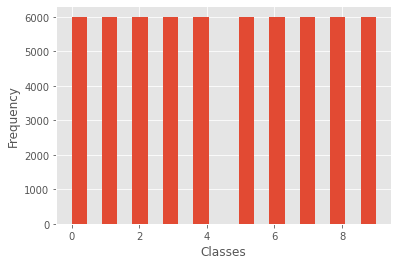

In [8]:
import matplotlib.pyplot as plt
value,idx=tf.unique(y_train)
print("......Total number of class is..............")
print(len(value))
print("\n.............Class labels are................")
print(value)
print("\n.............histogram plot of class labels............")
plt.style.use('ggplot')
plt.xlabel('Classes')
plt.ylabel('Frequency')
plt.hist(y_train,bins=20)

Now we split training dataset into data for training and validation.
**Validation dataset** is the sample of data used to provide an unbiased evaluation of a model fit on the training dataset while tuning model hyperparameters. Validation dataset is used to tune different hyperparameters so the model is unbiased. A model never learns from the validation dataset.

Here, we use sklearn `train_test_split` api to further split the training dataset.



In [ ]:
from sklearn import model_selection as ms

In [ ]:
x_train,x_val,y_train,y_val= ms.train_test_split(x_train,y_train,test_size=0.2,random_state=42)

In [ ]:
print(x_train.shape,y_train.shape)
print(x_val.shape,y_val.shape)

(48000, 28, 28) (48000,)
(12000, 28, 28) (12000,)


We can see that after the train-validation split,there are 48000 image samples in the final training set that will be used to train the model and 12000 image samples in the validation set that will be used to evaluate the model.


##3. Plotting training examples




In [ ]:
item_list=['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

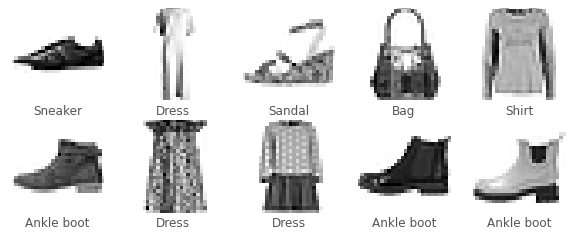

In [ ]:
# plot first few images
plt.figure(figsize=(10,10))
for i in range(10):
  plt.subplot(5,5,i+1)
  plt.xticks([])
  plt.yticks([])
  plt.imshow(x_train[i], cmap=plt.cm.binary)
  plt.xlabel(item_list[y_train[i]])
plt.show() 

Now we have training, validation and test data ready . Our next step is to build an image classification model using ANN.




##3. Building the ANN Model using Tensorflow

For this, we build a model with an input layer, 3 hidden layers and output layer.
The first hidden layer consist of 128 neurons, second hidden layer consists of 64 neurons and third hidden layer consists of 32 neurons. Input layer must consist 28*28=784 neurons as our input data dimension is fixed and output layer consist of 10 neurons (as we have 10 classes to classify as our target).


In [ ]:
# Let us initialize the weight matrix using knowledge from previous chapter

input_size = 28*28
output_size = 10
hidden_1_shape = 128
hidden_2_shape = 64
hidden_3_shape = 32


# initialize variables for weights
# for weight dimension refer to reading material of forward propagation 
weights = {
    'hidden_1': tf.Variable(tf.random.truncated_normal([input_size, hidden_1_shape]),trainable=True),
    'hidden_2': tf.Variable(tf.random.truncated_normal([hidden_1_shape, hidden_2_shape]),trainable=True),
    'hidden_3': tf.Variable(tf.random.truncated_normal([hidden_2_shape, hidden_3_shape]),trainable=True,),
    'output': tf.Variable(tf.random.truncated_normal([hidden_3_shape, output_size]),trainable=True),
    'hidden_1_bias': tf.Variable(tf.random.truncated_normal([hidden_1_shape]),trainable=True),
    'hidden_2_bias': tf.Variable(tf.random.truncated_normal([hidden_2_shape]),trainable=True),
    'hidden_3_bias': tf.Variable(tf.random.truncated_normal([hidden_3_shape]),trainable=True),
    'output_bias': tf.Variable(tf.random.truncated_normal([output_size]),trainable=True)
}

Before feeding the data to the model, let us reshape the train, test and validation dataset to make it compatible with the input layer of the model.


In [ ]:
x_train=tf.reshape(x_train,(-1,784))
x_val=tf.reshape(x_val,(-1,784))
x_test=tf.reshape(x_test,(-1,784))


In [ ]:
# let us check the final shapes
print(x_train.shape)
print(y_train.shape)

(48000, 784)
(48000,)


##4. Training the model

**Hyperparameter Tuning :**
 
 Parameters which define the model architecture are referred to as hyperparameters and thus this process of searching for the ideal model architecture is referred to as hyperparameter tuning.
 
Some basic example of hyperparameters can be :


*   What should be the value of learning rate  for gradient descent?

*   How many trees should I include in my random forest?

*   How many layers should my neural network have?

*   How many neurons should I have in my neural network layer?
etc and many more.


The most important and basic  concept  is that hyperparameters are not model parameters and they cannot be directly trained from the data. Model parameters are learned during training when we optimize a loss function using something like gradient descent.

**DL Model :** 

DL Model is  a trained (or yet to be trained) model which is expected to perform some intelligent stuff. For eg. A diabetes prediction model consist of neural net which can predict whether a person has diabetes when certain features are provided.




In [ ]:
# spliting  data into batch
def create_batch(x,y,batch_size):
  """
  Splits the data into batches.
 
  Parameters
  ----------
  x: list
    feature variable
  y: list
    target variable
  batch_size: int
    number of samples each batch consists
 
  Returns
  -------
  data split into batches
  """
  x = tf.cast(x,tf.float32)
  data = tf.data.Dataset.from_tensor_slices((x,y)).batch(batch_size)
  return data

In [ ]:
def train_epoch_by_epoch(data):
  """
  Forward propagation and backward propagation occours.
  tf.GradientTape records the trainable parameters during forward prop and adjusts gradients 
  during backword propagation.
  We use categorical loss which needs two parameters, actual label(one-hot encoded) 
  and prediction(which is output of softmax but here we use logits as 
  from_logits=True 
  as args given below)

  Parameters
  ----------
  data: tensor
    Train dataset
 
  Returns
  -------
  True after training process is completed
  """
  for i in data:
    with tf.GradientTape() as tape:
      fc_1 = tf.sigmoid(tf.add(tf.matmul(i[0], weights['hidden_1']), weights['hidden_1_bias']))
      fc_2 = tf.sigmoid(tf.add(tf.matmul(fc_1, weights['hidden_2']), weights['hidden_2_bias']))
      fc_3 = tf.sigmoid(tf.add(tf.matmul(fc_2, weights['hidden_3']), weights['hidden_3_bias']))
      output_layer = tf.add(tf.matmul(fc_3, weights['output']), weights['output_bias'])
      label = tf.one_hot(i[1],10)
      cost = loss(label,output_layer)
    grads = tape.gradient(cost, trainable_weights)
    optimizer.apply_gradients(zip(grads,trainable_weights))
  return True

In [ ]:
def eval_epoch_by_epoch(data):
  """
  Only forward propagates to evaluate training validation accuracy.

  Parameters
  ----------
  data: tensor
    Train dataset
 
  Returns
  -------
  Total cost per iteration and accuracy per iteration
  """
  
  tot_cost=0
  accuracy=0
  iter=0
  for i in data:
    size=(i[0].shape)[0]
    fc_1=tf.sigmoid(tf.add(tf.matmul(i[0], weights['hidden_1']), weights['hidden_1_bias']))
    fc_2=tf.sigmoid(tf.add(tf.matmul(fc_1, weights['hidden_2']), weights['hidden_2_bias']))
    fc_3=tf.sigmoid(tf.add(tf.matmul(fc_2, weights['hidden_3']), weights['hidden_3_bias']))
    output_layer=tf.add(tf.matmul(fc_3, weights['output']), weights['output_bias'])
    label=tf.one_hot(i[1],10)
    cost=loss(label,output_layer)
    tot_cost+=cost
    predicted=tf.argmax(output_layer,axis=1)
    label=tf.cast(i[1],tf.int64)
    res=tf.equal(predicted,label)
    mean_correct=tf.reduce_sum(tf.cast(res, tf.float32))/size
    accuracy+=mean_correct
    iter+=1
  return(tot_cost/iter,accuracy/iter)


In [ ]:
# sanity check
# here we take one batch of size 128 and over train it to check whether it 
#overfits or not. Here accuracy gradually increases and if over-trained it 
# overfits and accuracy may reach 100% for this batch.

learning_rate=0.001
epoch=200
batch_size=128
loss=tf.losses.CategoricalCrossentropy(from_logits=True)
optimizer=tf.optimizers.Adam(learning_rate)


trainable_weights=[]
for i in weights:
  trainable_weights.append(weights[i])

for i in range(epoch):
  train_data=create_batch(x_train,y_train,batch_size)
  train_data=iter(train_data)
  train_data=[next(train_data)]
  train_epoch_by_epoch(train_data)
  train_cost,train_acc=eval_epoch_by_epoch(train_data)
  if(i%10==0):
    print(f"Epoch :({i}/{epoch}) Train_Cost :{train_cost:.5f}  Train_accuracy :{train_acc:.3f} ")


Epoch :(0/200) Train_Cost :6.40138  Train_accuracy :0.141 
Epoch :(10/200) Train_Cost :5.03511  Train_accuracy :0.141 
Epoch :(20/200) Train_Cost :4.20633  Train_accuracy :0.133 
Epoch :(30/200) Train_Cost :3.55830  Train_accuracy :0.164 
Epoch :(40/200) Train_Cost :2.88539  Train_accuracy :0.164 
Epoch :(50/200) Train_Cost :2.32102  Train_accuracy :0.211 
Epoch :(60/200) Train_Cost :2.01110  Train_accuracy :0.344 
Epoch :(70/200) Train_Cost :1.80462  Train_accuracy :0.430 
Epoch :(80/200) Train_Cost :1.66248  Train_accuracy :0.477 
Epoch :(90/200) Train_Cost :1.54412  Train_accuracy :0.547 
Epoch :(100/200) Train_Cost :1.43834  Train_accuracy :0.562 
Epoch :(110/200) Train_Cost :1.34116  Train_accuracy :0.609 
Epoch :(120/200) Train_Cost :1.24862  Train_accuracy :0.656 
Epoch :(130/200) Train_Cost :1.15976  Train_accuracy :0.727 
Epoch :(140/200) Train_Cost :1.07740  Train_accuracy :0.734 
Epoch :(150/200) Train_Cost :1.00219  Train_accuracy :0.773 
Epoch :(160/200) Train_Cost :0.9330

In [ ]:
# here the call for training begins.

learning_rate=0.001
epoch=300
batch_size=128
loss=tf.losses.CategoricalCrossentropy(from_logits=True)
optimizer=tf.optimizers.Adam(learning_rate)

trainable_weights=[]
for i in weights:
  trainable_weights.append(weights[i])

for i in range(epoch):
  train_data=create_batch(x_train,y_train,batch_size)
  train_epoch_by_epoch(train_data)
  if(i%10==0):
    val_data=create_batch(x_val,y_val,batch_size)
    train_cost,train_acc=eval_epoch_by_epoch(train_data)
    val_cost,val_acc=eval_epoch_by_epoch(val_data)

    print(f"Epoch :({i}/{epoch}) Train_Cost :{train_cost:.5f} Val_Cost :{val_cost:.5f} Train_accuracy :{train_acc:.3f}  Val_accuracy :{val_acc:.3f} ")

Epoch :(0/300) Train_Cost :0.94166 Val_Cost :0.96193 Train_accuracy :0.664  Val_accuracy :0.657 
Epoch :(10/300) Train_Cost :0.60382 Val_Cost :0.62458 Train_accuracy :0.779  Val_accuracy :0.774 
Epoch :(20/300) Train_Cost :0.56031 Val_Cost :0.57522 Train_accuracy :0.791  Val_accuracy :0.785 
Epoch :(30/300) Train_Cost :0.55112 Val_Cost :0.57998 Train_accuracy :0.796  Val_accuracy :0.784 
Epoch :(40/300) Train_Cost :0.52593 Val_Cost :0.54795 Train_accuracy :0.805  Val_accuracy :0.795 
Epoch :(50/300) Train_Cost :0.50492 Val_Cost :0.53049 Train_accuracy :0.813  Val_accuracy :0.807 
Epoch :(60/300) Train_Cost :0.49129 Val_Cost :0.52126 Train_accuracy :0.818  Val_accuracy :0.808 
Epoch :(70/300) Train_Cost :0.49079 Val_Cost :0.51939 Train_accuracy :0.814  Val_accuracy :0.807 
Epoch :(80/300) Train_Cost :0.47670 Val_Cost :0.50599 Train_accuracy :0.823  Val_accuracy :0.812 
Epoch :(90/300) Train_Cost :0.46766 Val_Cost :0.49167 Train_accuracy :0.826  Val_accuracy :0.816 
Epoch :(100/300) Trai

##5. Testing the model


In [ ]:
# here we create batch of test data and forward it to model to get test accuracy
test_data=create_batch(x_test,y_test,128)
test_cost,test_acc=eval_epoch_by_epoch(test_data)
print("Test Accuracy :",test_acc.numpy()*100)

Test Accuracy : 83.08939933776855
